# Phase 4: Exploratory Data Analysis and Data Cleaning

**Member:** Member 2  
**Input:** `data/interim/integrated_cars_raw.csv`  
**Output:** `data/processed/cleaned_cars.csv`


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns

pd.set_option("display.max_columns", None)

df = pd.read_csv("../data/interim/integrated_cars_raw.csv", low_memory=False)

print("Dataset shape:", df.shape)
display(df.head())
df.info()

Dataset shape: (295454, 14)


,make,model,year,mileage,condition,cylinders,fuel,title_status,transmission,drive,size,type,price,data_source
0,ford,explorer st,2022.0,99179.0,excellent,6 cylinders,gas,clean,automatic,4wd,NaN,SUV,27999,kaggle
1,volkswagen,bug,1969.0,90000.0,fair,4 cylinders,gas,clean,manual,rwd,NaN,other,2200,kaggle
2,rover,sport,2016.0,82896.0,excellent,6 cylinders,gas,clean,automatic,4wd,NaN,SUV,15999,kaggle
3,cadillac,eldorado convertible,1974.0,89687.0,good,8 cylinders,gas,clean,automatic,fwd,NaN,convertible,12000,kaggle
4,dodge,challenger lc srt8,2009.0,81724.0,excellent,8 cylinders,gas,clean,automatic,rwd,NaN,coupe,18999,kaggle


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 295454 entries, 0 to 295453
Data columns (total 14 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   make          284662 non-null  object 
 1   model         292095 non-null  object 
 2   year          295428 non-null  float64
 3   mileage       291415 non-null  float64
 4   condition     159961 non-null  object 
 5   cylinders     215284 non-null  object 
 6   fuel          294320 non-null  object 
 7   title_status  288635 non-null  object 
 8   transmission  293895 non-null  object 
 9   drive         225076 non-null  object 
 10  size          0 non-null       float64
 11  type          279642 non-null  object 
 12  price         295454 non-null  object 
 13  data_source   295454 non-null  object 
dtypes: float64(3), object(11)
memory usage: 31.6+ MB


## 1. Data Quality Assessment

Checking missing values, duplicate rows, data types, and the raw format of price values.

In [2]:
# Missing values
print("Missing values per column:")
display(df.isnull().sum())

# Missing values percentage
print("\nMissing values percentage:")
display((df.isnull().sum() / len(df) * 100).round(2))

# Duplicate rows
print(f"\nDuplicate rows: {df.duplicated().sum()}")

# Unique values in each column
print("\nUnique values per column:")
display(df.nunique())

# Inspect raw values inside the price column
print("\nSample raw price values:")
display(df["price"].dropna().sample(20, random_state=42))

Missing values per column:


make             10792
model             3359
year                26
mileage           4039
condition       135493
cylinders        80170
fuel              1134
title_status      6819
transmission      1559
drive            70378
size            295454
type             15812
price                0
data_source          0
dtype: int64


Missing values percentage:


make              3.65
model             1.14
year              0.01
mileage           1.37
condition        45.86
cylinders        27.13
fuel              0.38
title_status      2.31
transmission      0.53
drive            23.82
size            100.00
type              5.35
price             0.00
data_source       0.00
dtype: float64


Duplicate rows: 102421

Unique values per column:


make               42
model           27958
year              114
mileage         83749
condition           6
cylinders           8
fuel                5
title_status        6
transmission        3
drive               3
size                0
type               13
price           15574
data_source         2
dtype: int64


Sample raw price values:


254660    22995
116476        0
227754    26949
154415    23900
107145     6995
271662     2000
73348      1295
18504     33700
42583         1
116366        0
153933    19995
188548    75900
197023     5995
253131     2700
151577        1
273702     5395
39124     20995
220419     9479
70403      7500
91120     39997
Name: price, dtype: object

## 2. Duplicate and Price Investigation

Investigating duplicate records and identifying invalid or non-numeric price values before applying cleaning rules.

In [3]:
# Duplicate analysis
print("Exact duplicate rows:", df.duplicated().sum())

print("\nDuplicate rows by data source:")
display(
    df[df.duplicated(keep=False)]
    .groupby("data_source")
    .size()
    .rename("duplicate_rows")
)

# Check whether duplicate values differ only by data source
duplicates_without_source = df.duplicated(
    subset=["make", "model", "year", "price"],
    keep=False
).sum()

print(f"\nRows duplicated based on make, model, year, and price: {duplicates_without_source}")

# Price type analysis
print("\nPython types found in price:")
display(df["price"].map(type).value_counts())

# Convert price temporarily, without changing df yet
price_numeric_check = pd.to_numeric(df["price"], errors="coerce")

print("\nPrice values that cannot be converted to numbers:")
display(df.loc[price_numeric_check.isna(), "price"].drop_duplicates().head(30))

print(f"\nNon-numeric price values count: {price_numeric_check.isna().sum()}")
print(f"Prices less than or equal to zero: {(price_numeric_check <= 0).sum()}")
print(f"Prices equal to 1: {(price_numeric_check == 1).sum()}")

Exact duplicate rows: 102421

Duplicate rows by data source:


data_source
kaggle    143760
Name: duplicate_rows, dtype: int64


Rows duplicated based on make, model, year, and price: 163148

Python types found in price:


price
<class 'str'>    295454
Name: count, dtype: int64


Price values that cannot be converted to numbers:


Series([], Name: price, dtype: object)


Non-numeric price values count: 0
Prices less than or equal to zero: 10288
Prices equal to 1: 637


## 3. Initial Cleaning and Numeric Validation

Creating a clean working copy, removing exact duplicates, converting price to numeric, and inspecting invalid price and year values.

In [4]:
# Create a separate working copy
df_clean = df.copy()

# Remove only fully identical duplicate rows
rows_before_duplicates = len(df_clean)
df_clean = df_clean.drop_duplicates().copy()

print(f"Rows before removing exact duplicates: {rows_before_duplicates:,}")
print(f"Rows after removing exact duplicates:  {len(df_clean):,}")
print(f"Removed duplicate rows:               {rows_before_duplicates - len(df_clean):,}")

# Make price numeric
df_clean["price"] = pd.to_numeric(df_clean["price"], errors="coerce")

# Check suspicious price values
print("\nPrice values less than or equal to 1:")
display(df_clean.loc[df_clean["price"] <= 1, ["make", "model", "year", "price", "data_source"]].head(20))

print("\nCount for each price value <= 1:")
display(df_clean.loc[df_clean["price"] <= 1, "price"].value_counts().sort_index())

# Year validation
print("\nYear range:")
print("Minimum year:", df_clean["year"].min())
print("Maximum year:", df_clean["year"].max())

print("\nRows with missing or suspicious years:")
display(
    df_clean.loc[
        df_clean["year"].isna() | (df_clean["year"] < 1886) | (df_clean["year"] > 2026),
        ["make", "model", "year", "price", "data_source"]
    ].head(30)
)

Rows before removing exact duplicates: 295,454
Rows after removing exact duplicates:  193,033
Removed duplicate rows:               102,421

Price values less than or equal to 1:


,make,model,year,price,data_source
49,ford,f-150 xlt,2026.0,0.0,kaggle
83,ford,bronco sport big bend,2026.0,0.0,kaggle
101,mercedes-benz,gle350,2023.0,0.0,kaggle
327,honda,accord lx sedan 4d,2011.0,0.0,kaggle
332,lexus,nx,2020.0,0.0,kaggle
333,mazda,cx 30,2025.0,0.0,kaggle
338,mini,hardtop 4 door cooper hatc,2015.0,0.0,kaggle
370,lexus,rc,2016.0,0.0,kaggle
371,lexus,gs,2015.0,0.0,kaggle
372,lexus,rx,2023.0,0.0,kaggle



Count for each price value <= 1:


price
0.0    6286
1.0     459
Name: count, dtype: int64


Year range:
Minimum year: 1900.0
Maximum year: 2027.0

Rows with missing or suspicious years:


,make,model,year,price,data_source
456,ford,expedition max platinum,2027.0,1658.0,kaggle
577,toyota,corolla le,2027.0,0.0,kaggle
606,toyota,camry se,2027.0,0.0,kaggle
857,ford,super duty f-350 srw xl,2027.0,1092.0,kaggle
895,ford,super duty f-350 srw xl,2027.0,1091.0,kaggle
934,toyota,camry hybrid le,2027.0,29999.0,kaggle
2384,ford,super duty f-250 srw xl,2027.0,974.0,kaggle
2848,ford,super duty f-350 lariat,2027.0,1816.0,kaggle
2938,ford,transit van,2027.0,1193.0,kaggle
3348,toyota,corolla hybrid le,2027.0,0.0,kaggle


## 4. Core Cleaning Rules

- Remove exact duplicate records.
- Drop the completely empty `size` column.
- Remove records with invalid target prices (`price` <= 1).
- Remove records with missing or invalid year values (`year` < 1886 or `year` > 2026).
- Remove records with missing or invalid mileage values (`mileage` <= 0 or `mileage` > 500,000).
- Standardize text fields and mark missing categorical values as `unknown`.

In [5]:
df_clean = df_clean.drop(columns=["size"], errors="ignore")

rows_before_price_cleaning = len(df_clean)
df_clean = df_clean[df_clean["price"] > 1].copy()
print(f"Removed rows with price <= 1: {rows_before_price_cleaning - len(df_clean):,}")

rows_before_year_cleaning = len(df_clean)
df_clean = df_clean[df_clean["year"].notna() & df_clean["year"].between(1886, 2026)].copy()
print(f"Removed rows with missing or invalid year: {rows_before_year_cleaning - len(df_clean):,}")
df_clean["year"] = df_clean["year"].astype("int64")

if "mileage" in df_clean.columns:
    rows_before_mileage_cleaning = len(df_clean)
    df_clean["mileage"] = pd.to_numeric(df_clean["mileage"], errors="coerce")
    df_clean = df_clean[df_clean["mileage"].notna() & df_clean["mileage"].between(1, 500_000)].copy()
    print(f"Removed rows with missing or invalid mileage: {rows_before_mileage_cleaning - len(df_clean):,}")
    df_clean["mileage"] = df_clean["mileage"].round().astype("int64")

cat_cols = [
    "make", "model", "condition", "cylinders", "fuel",
    "title_status", "transmission", "drive", "type",
    "paint_color", "state"
]
for column in cat_cols:
    if column in df_clean.columns:
        df_clean[column] = (
            df_clean[column]
            .fillna("unknown")
            .astype(str)
            .str.strip()
            .str.lower()
            .replace({"": "unknown", "nan": "unknown", "none": "unknown"})
        )

print("\nCleaned dataset shape:", df_clean.shape)

print("\nMissing values after core cleaning:")
display(df_clean.isnull().sum())

print("\nInvalid prices remaining (<= 1):", (df_clean["price"] <= 1).sum())
print("Duplicate rows remaining:", df_clean.duplicated().sum())

print("\nMissing-category counts:")
print("make = unknown:", (df_clean["make"] == "unknown").sum())
print("model = unknown:", (df_clean["model"] == "unknown").sum())

Removed rows with price <= 1: 6,745
Removed rows with missing or invalid year: 320
Removed rows with missing or invalid mileage: 1,700

Cleaned dataset shape: (184268, 13)

Missing values after core cleaning:


make            0
model           0
year            0
mileage         0
condition       0
cylinders       0
fuel            0
title_status    0
transmission    0
drive           0
type            0
price           0
data_source     0
dtype: int64


Invalid prices remaining (<= 1): 0
Duplicate rows remaining: 11

Missing-category counts:
make = unknown: 7153
model = unknown: 2144


## 5. Final Duplicate Removal

Removing duplicates that became identical after standardizing make and model values.

In [6]:
# Remove duplicates created after text standardization
rows_before_final_deduplication = len(df_clean)

df_clean = df_clean.drop_duplicates().copy()

final_duplicates_removed = rows_before_final_deduplication - len(df_clean)

print(f"Duplicates removed after text standardization: {final_duplicates_removed:,}")
print(f"Final cleaned dataset shape: {df_clean.shape}")
print(f"Remaining duplicate rows: {df_clean.duplicated().sum()}")

print("\nFinal rows by data source:")
display(df_clean["data_source"].value_counts())

print("\nFinal data types:")
display(df_clean.dtypes)

Duplicates removed after text standardization: 11
Final cleaned dataset shape: (184257, 13)
Remaining duplicate rows: 0

Final rows by data source:


data_source
kaggle    184257
Name: count, dtype: int64


Final data types:


make             object
model            object
year              int64
mileage           int64
condition        object
cylinders        object
fuel             object
title_status     object
transmission     object
drive            object
type             object
price           float64
data_source      object
dtype: object

## 6. Price Distribution and Outlier Analysis

Exploring the target variable (`price`) using descriptive statistics, histograms, and boxplots, and filtering invalid extreme prices outside the `$500`–`$500,000` range.

count    1.842570e+05
mean     5.427202e+18
std      2.329636e+21
min      2.000000e+00
25%      5.999000e+03
50%      1.145000e+04
75%      1.999000e+04
max      1.000000e+24
Name: price, dtype: float64

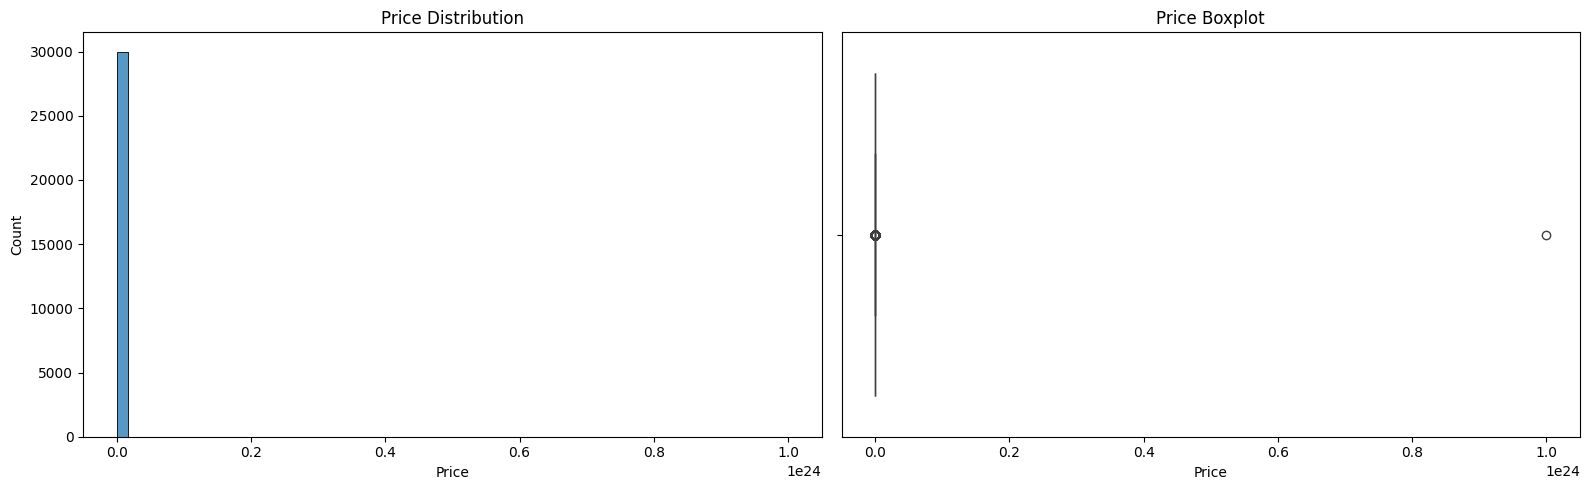

In [7]:
# Price summary
display(df_clean["price"].describe())

# Use a sample for faster plotting
plot_prices = df_clean["price"].sample(30000, random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.histplot(plot_prices, bins=60, kde=False, ax=axes[0])
axes[0].set_title("Price Distribution")
axes[0].set_xlabel("Price")

sns.boxplot(x=plot_prices, ax=axes[1])
axes[1].set_title("Price Boxplot")
axes[1].set_xlabel("Price")

plt.tight_layout()
plt.show()

In [8]:
# Inspect extremely high and likely invalid prices
high_price_threshold = 500_000

suspicious_high_prices = df_clean[df_clean["price"] > high_price_threshold].copy()

print("Number of prices above $500,000:", len(suspicious_high_prices))
print(
    "Percentage of dataset:",
    round(len(suspicious_high_prices) / len(df_clean) * 100, 4),
    "%"
)

display(
    suspicious_high_prices
    .sort_values("price", ascending=False)
    [["make", "model", "year", "price", "data_source"]]
    .head(30)
)

print("\nHighest 20 distinct price values:")
display(df_clean["price"].sort_values(ascending=False).head(20))

Number of prices above $500,000: 35
Percentage of dataset: 0.019 %


,make,model,year,price,data_source
120108,mazda,protege,2001,1.000000e+24,kaggle
50847,ford,f-150,1991,1.111111e+16,kaggle
168494,chevrolet,unknown,2017,1.111111e+11,kaggle
34758,ram,2500hd,2007,1.000000e+09,kaggle
55474,chevrolet,silverado 2500,2016,9.876543e+08,kaggle
291379,ram,3500,2002,9.876543e+08,kaggle
55472,chevrolet,silverado,2012,9.876543e+08,kaggle
51492,cadillac,xt6,2020,1.234568e+08,kaggle
18758,gmc,c4500,2003,1.234568e+08,kaggle
51056,chevrolet,sonic lt,2020,1.234568e+08,kaggle



Highest 20 distinct price values:


120108    1.000000e+24
50847     1.111111e+16
168494    1.111111e+11
34758     1.000000e+09
291379    9.876543e+08
55474     9.876543e+08
55472     9.876543e+08
18758     1.234568e+08
51047     1.234568e+08
51492     1.234568e+08
51056     1.234568e+08
270539    1.234568e+08
51354     1.234565e+08
134338    1.111111e+08
14102     1.000000e+08
51463     1.234568e+07
51465     1.234568e+07
231635    1.111111e+07
222380    9.999999e+06
84998     9.999999e+06
Name: price, dtype: float64

In [9]:
df_clean = df_clean[df_clean["price"] <= 500_000].copy()

print("Dataset shape:", df_clean.shape)
print("Maximum remaining price:", df_clean["price"].max())

Dataset shape: (184222, 13)
Maximum remaining price: 500000.0


count    184222.000000
mean      15812.767731
std       17203.223835
min           2.000000
25%        5999.000000
50%       11446.000000
75%       19990.000000
max      500000.000000
Name: price, dtype: float64

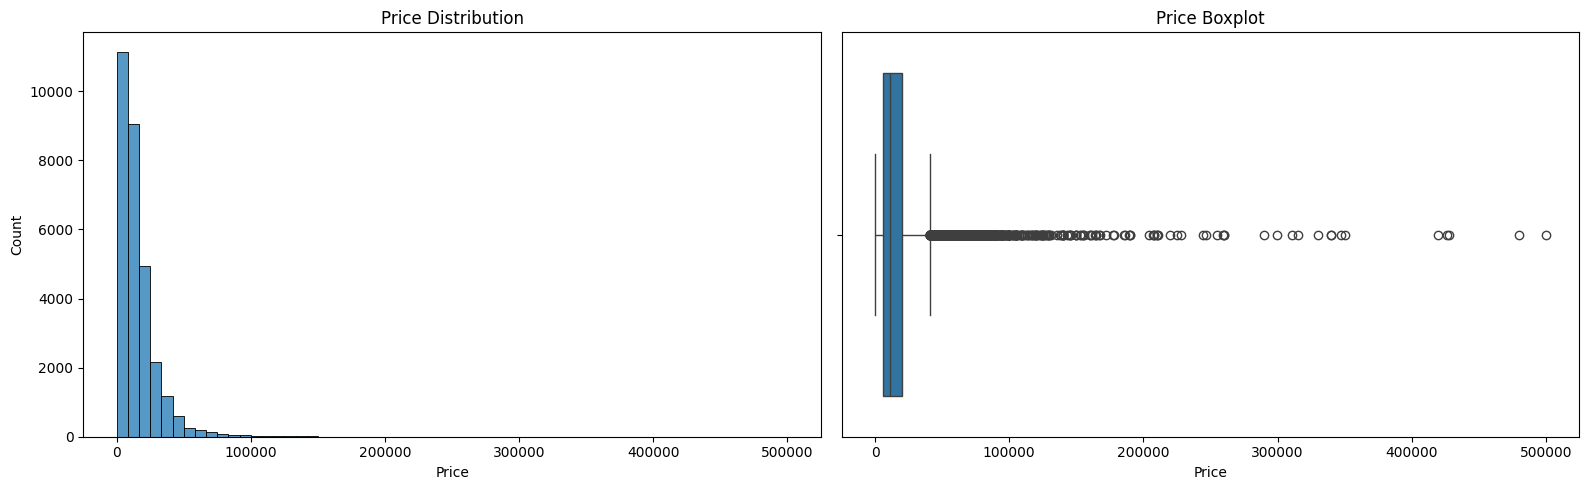

In [10]:
display(df_clean["price"].describe())

plot_prices = df_clean["price"].sample(30000, random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.histplot(plot_prices, bins=60, kde=False, ax=axes[0])
axes[0].set_title("Price Distribution")
axes[0].set_xlabel("Price")

sns.boxplot(x=plot_prices, ax=axes[1])
axes[1].set_title("Price Boxplot")
axes[1].set_xlabel("Price")

plt.tight_layout()
plt.show()

In [11]:
low_price_threshold = 500

suspicious_low_prices = df_clean[df_clean["price"] < low_price_threshold].copy()

print("Number of prices below $500:", len(suspicious_low_prices))
print(
    "Percentage of dataset:",
    round(len(suspicious_low_prices) / len(df_clean) * 100, 4),
    "%"
)

display(
    suspicious_low_prices
    .sort_values("price")
    [["make", "model", "year", "price", "data_source"]]
    .head(30)
)

Number of prices below $500: 1421
Percentage of dataset: 0.7714 %


,make,model,year,price,data_source
4152,dodge,m37,1952,2.0,kaggle
71799,unknown,avalanche,2003,2.0,kaggle
8466,ford,f-150 lightning flash,2024,2.0,kaggle
33042,toyota,sienna,2002,2.0,kaggle
8908,gmc,terrain slt,2024,2.0,kaggle
162135,chevrolet,malibu lt,2012,2.0,kaggle
165755,toyota,corolla,2013,2.0,kaggle
190253,dodge,dart gt,1963,2.0,kaggle
129012,chevrolet,impala,2003,3.0,kaggle
240110,chevrolet,unknown,2025,3.0,kaggle


In [12]:
df_clean = df_clean[
    df_clean["price"].between(500, 500_000)
].copy()
df_clean["price"] = df_clean["price"].round().astype("int64")

print("Dataset shape after price range filtering:", df_clean.shape)
print("Minimum remaining price:", df_clean["price"].min())
print("Maximum remaining price:", df_clean["price"].max())

Dataset shape after price range filtering: (182801, 13)
Minimum remaining price: 500
Maximum remaining price: 500000


## 7. Final Data Validation

Validating that the cleaned dataset has no missing values, duplicates, invalid prices, empty text values, or invalid years.

In [13]:
validation_results = {
    "missing_values": int(df_clean.isna().sum().sum()),
    "duplicate_rows": int(df_clean.duplicated().sum()),
    "prices_below_500": int((df_clean["price"] < 500).sum()),
    "prices_above_500000": int((df_clean["price"] > 500_000).sum()),
    "empty_make_values": int((df_clean["make"].str.strip() == "").sum()),
    "empty_model_values": int((df_clean["model"].str.strip() == "").sum()),
    "years_before_1886": int((df_clean["year"] < 1886).sum()),
    "years_after_2026": int((df_clean["year"] > 2026).sum()),
    "invalid_mileage_values": int((~df_clean["mileage"].between(1, 500_000)).sum()) if "mileage" in df_clean.columns else 0,
    "invalid_data_source_values": int(
        (~df_clean["data_source"].isin(["kaggle", "web_scraped"])).sum()
    ),
}

validation_report = pd.DataFrame.from_dict(
    validation_results,
    orient="index",
    columns=["invalid_count"]
)

validation_report["status"] = np.where(
    validation_report["invalid_count"] == 0,
    "PASS",
    "CHECK"
)

display(validation_report)

print("\nDataset shape:", df_clean.shape)
print("Year range:", df_clean["year"].min(), "to", df_clean["year"].max())
print("Price range:", df_clean["price"].min(), "to", df_clean["price"].max())
if "mileage" in df_clean.columns:
    print("Mileage range:", df_clean["mileage"].min(), "to", df_clean["mileage"].max())

print("\nData source counts:")
display(df_clean["data_source"].value_counts())

print("\nRows with unknown categories (allowed, but documented):")
print("Unknown make:", (df_clean["make"] == "unknown").sum())
print("Unknown model:", (df_clean["model"] == "unknown").sum())

,invalid_count,status
missing_values,0,PASS
duplicate_rows,0,PASS
prices_below_500,0,PASS
prices_above_500000,0,PASS
empty_make_values,0,PASS
empty_model_values,0,PASS
years_before_1886,0,PASS
years_after_2026,0,PASS
invalid_mileage_values,0,PASS
invalid_data_source_values,0,PASS



Dataset shape: (182801, 13)
Year range: 1900 to 2026
Price range: 500 to 500000
Mileage range: 1 to 500000

Data source counts:


data_source
kaggle    182801
Name: count, dtype: int64


Rows with unknown categories (allowed, but documented):
Unknown make: 7017
Unknown model: 2106


## 8. Save Cleaned Dataset

**Input dataset:** `data/interim/integrated_cars_raw.csv`  
**Output dataset:** `data/processed/cleaned_cars.csv`

Cleaning steps applied:

- Removed exact duplicate records, including duplicates revealed after standardizing text values.
- Dropped the completely empty `size` column (retaining 13 clean columns).
- Converted `price`, `year`, and `mileage` to numeric integer types (`int64`).
- Removed rows with missing or invalid `year` values outside `1886`–`2026`.
- Removed rows with missing or invalid `mileage` values outside `1`–`500,000` miles.
- Replaced missing categorical values across all text columns with `unknown` and standardized formatting (`lowercase`).
- Removed invalid target prices outside the accepted range:
  - Below `$500`
  - Above `$500,000`

Final validation passed:

- Zero missing values (`0` NaNs)
- Zero duplicate rows
- All prices within `$500` to `$500,000`
- Valid `year` (`1886`–`2026`) and `mileage` (`1`–`500,000`) values only
- Retained `182,799` clean rows across `13` columns (all originating from the `kaggle` data source after filtering)

In [14]:
output_path = "../data/processed/cleaned_cars.csv"

df_clean.to_csv(output_path, index=False)

print(f"Cleaned dataset saved successfully to: {output_path}")

# Verification: read the saved file and confirm its shape
saved_df = pd.read_csv(output_path)

print("Saved dataset shape:", saved_df.shape)
display(saved_df.head())

Cleaned dataset saved successfully to: ../data/processed/cleaned_cars.csv
Saved dataset shape: (182801, 13)


,make,model,year,mileage,condition,cylinders,fuel,title_status,transmission,drive,type,price,data_source
0,ford,explorer st,2022,99179,excellent,6 cylinders,gas,clean,automatic,4wd,suv,27999,kaggle
1,volkswagen,bug,1969,90000,fair,4 cylinders,gas,clean,manual,rwd,other,2200,kaggle
2,rover,sport,2016,82896,excellent,6 cylinders,gas,clean,automatic,4wd,suv,15999,kaggle
3,cadillac,eldorado convertible,1974,89687,good,8 cylinders,gas,clean,automatic,fwd,convertible,12000,kaggle
4,dodge,challenger lc srt8,2009,81724,excellent,8 cylinders,gas,clean,automatic,rwd,coupe,18999,kaggle


## 9. Exploratory Data Analysis

### Vehicle Years and Most Common Makes

Year summary:


count    182801.000000
mean       2011.952796
std          11.909084
min        1900.000000
25%        2009.000000
50%        2015.000000
75%        2019.000000
max        2026.000000
Name: year, dtype: float64

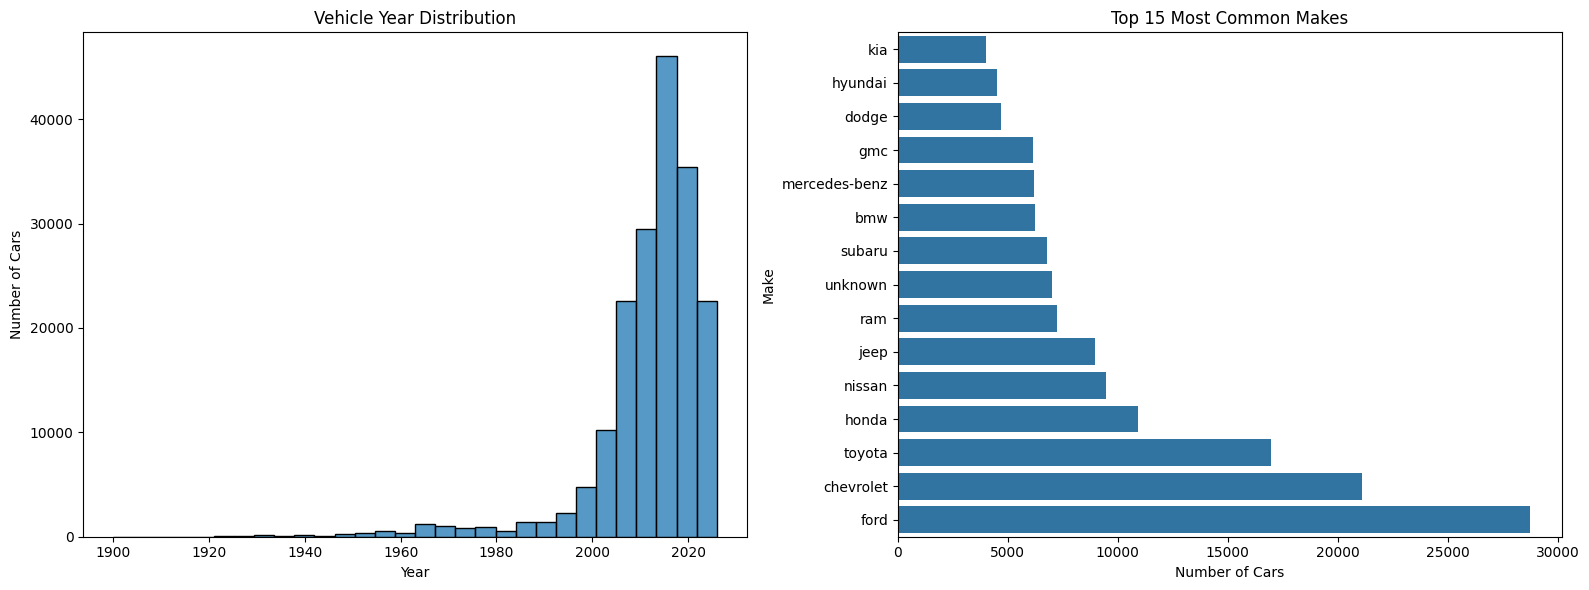

In [15]:
print("Year summary:")
display(df_clean["year"].describe())

top_makes = df_clean["make"].value_counts().head(15).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.histplot(df_clean["year"], bins=30, ax=axes[0])
axes[0].set_title("Vehicle Year Distribution")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Number of Cars")

sns.barplot(
    x=top_makes.values,
    y=top_makes.index,
    ax=axes[1]
)
axes[1].set_title("Top 15 Most Common Makes")
axes[1].set_xlabel("Number of Cars")
axes[1].set_ylabel("Make")

plt.tight_layout()
plt.show()

### Relationship Between Vehicle Year and Price

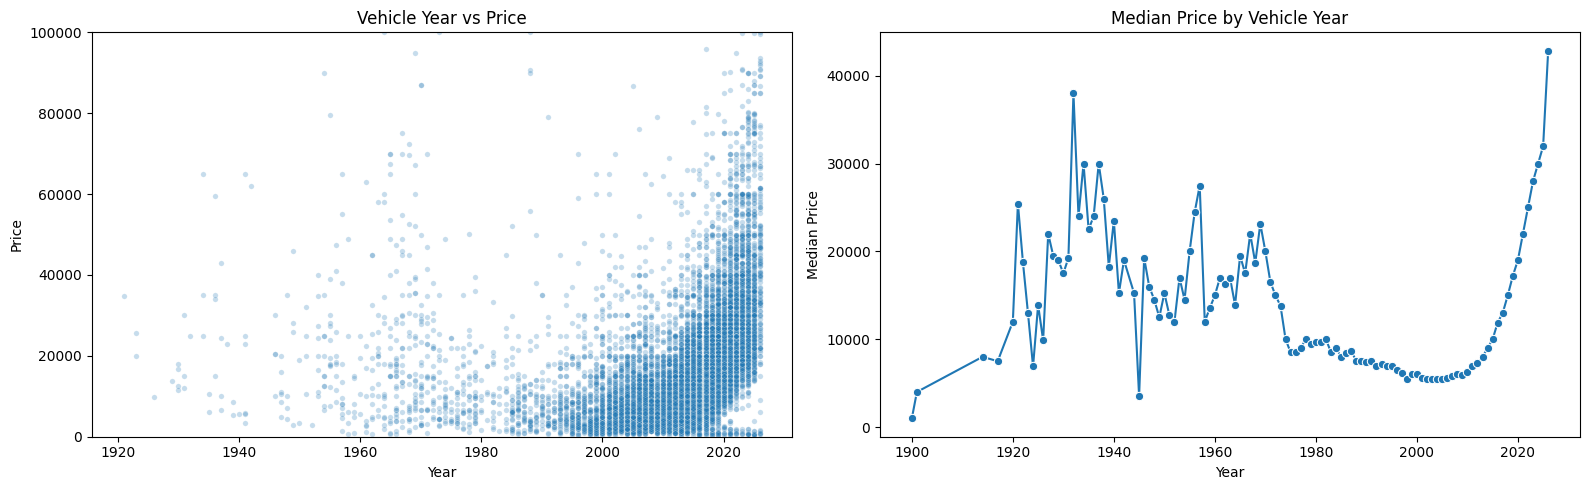

In [16]:
# Sample for a clear scatter plot
year_price_sample = df_clean.sample(15000, random_state=42)

# Median price for every model year
median_price_by_year = (
    df_clean.groupby("year", as_index=False)["price"]
    .median()
)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.scatterplot(
    data=year_price_sample,
    x="year",
    y="price",
    alpha=0.25,
    s=15,
    ax=axes[0]
)
axes[0].set_title("Vehicle Year vs Price")
axes[0].set_ylim(0, 100000)
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Price")

sns.lineplot(
    data=median_price_by_year,
    x="year",
    y="price",
    marker="o",
    ax=axes[1]
)
axes[1].set_title("Median Price by Vehicle Year")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Median Price")

plt.tight_layout()
plt.show()

### Price Comparison Across Common Makes

,make,car_count,median_price,mean_price
6,nissan,9474,7995.0,10035.577370
3,honda,10915,10500.0,12501.322034
8,subaru,6807,10999.0,12785.871603
0,bmw,6223,11900.0,17164.168247
4,jeep,8957,11999.0,14081.840907
1,chevrolet,21091,12495.0,16716.661751
5,mercedes-benz,6215,12500.0,19279.619308
2,ford,28749,12500.0,17194.027757
9,toyota,16970,12999.0,16315.969711
7,ram,7243,19500.0,22895.608588


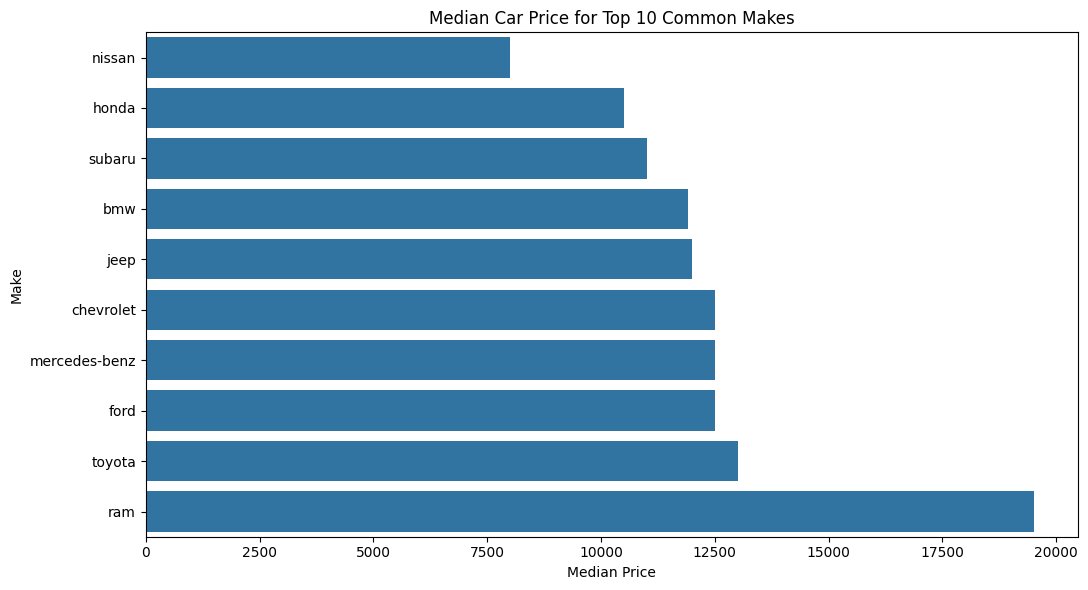

In [17]:
# Select the 10 most common known makes
top_10_known_makes = (
    df_clean[df_clean["make"] != "unknown"]["make"]
    .value_counts()
    .head(10)
    .index
)

make_price_summary = (
    df_clean[df_clean["make"].isin(top_10_known_makes)]
    .groupby("make", as_index=False)
    .agg(
        car_count=("price", "size"),
        median_price=("price", "median"),
        mean_price=("price", "mean")
    )
    .sort_values("median_price")
)

display(make_price_summary)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=make_price_summary,
    x="median_price",
    y="make"
)

plt.title("Median Car Price for Top 10 Common Makes")
plt.xlabel("Median Price")
plt.ylabel("Make")
plt.tight_layout()
plt.show()

### Price vs. Mileage and Condition Analysis

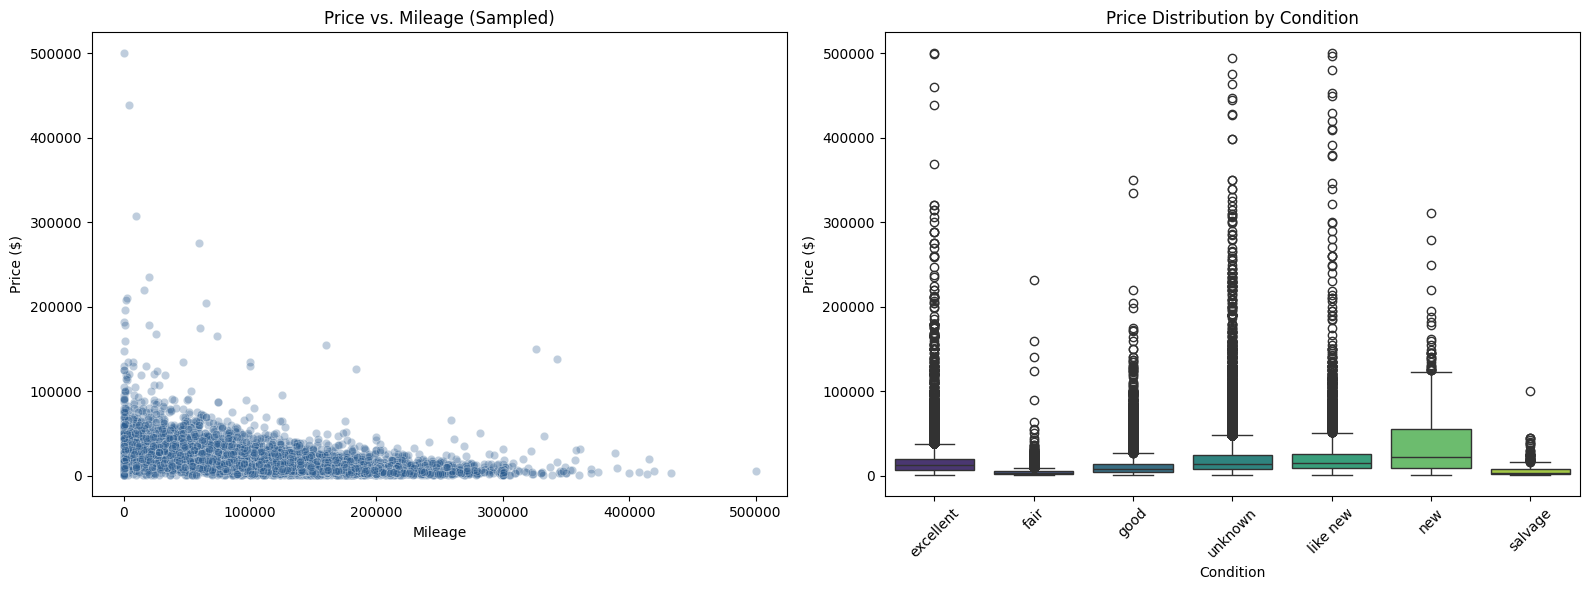

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sample_df = df_clean.sample(n=min(10000, len(df_clean)), random_state=42)
sns.scatterplot(data=sample_df, x="mileage", y="price", alpha=0.3, ax=axes[0], color="#2b5c8f")
axes[0].set_title("Price vs. Mileage (Sampled)")
axes[0].set_xlabel("Mileage")
axes[0].set_ylabel("Price ($)")

sns.boxplot(data=df_clean, x="condition", y="price", hue="condition", ax=axes[1], palette="viridis", legend=False)
axes[1].set_title("Price Distribution by Condition")
axes[1].set_xlabel("Condition")
axes[1].set_ylabel("Price ($)")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

## EDA Findings

- The final cleaned dataset contains 13 columns (after dropping the empty `size` column) with zero missing values.
- Price is right-skewed: the median price is lower than the mean price.
- Most vehicles were manufactured between 2008 and 2019, with a median model year of 2015.
- Newer vehicles generally have higher prices, although the relationship varies by vehicle type and make.
- Ford, Chevrolet, and Toyota are the most frequent known makes in the dataset.
- Median prices differ across makes; Ram and GMC have higher median prices among the most common makes, while Nissan has the lowest.
- `make`, `model`, `year`, and `mileage` are key features for price prediction.